# Churn Prediction and Risk Scoring

Predict which customers of an online retailer will **stop buying** in the next 90 days, using the
[Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii) transactions (Dec 2009 - Dec 2011).

**Plan**
1. Define churn and build a customer table (features + label) at several cutoff dates
2. Train a Logistic Regression baseline, a Random Forest and XGBoost
3. Evaluate with precision, recall, PR-AUC and bootstrap confidence intervals
4. Compare decision thresholds (missed churners vs false alerts)
5. Look at false positives / false negatives
6. Explain predictions with SHAP

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, precision_recall_curve, confusion_matrix,
                             ConfusionMatrixDisplay)
from xgboost import XGBClassifier
import warnings
warnings.filterwarnings("ignore")
import shap

pd.set_option("display.float_format", "{:.3f}".format)

## 1. Load and clean the data

The raw file `online_retail_II.xlsx` has two sheets (2009-2010 and 2010-2011), one row per product line of an invoice.
Reading the Excel file takes 1-2 minutes.

In [2]:
sheets = pd.read_excel("online_retail_II.xlsx", sheet_name=None, dtype={"Invoice": str, "StockCode": str})
raw = pd.concat(sheets.values(), ignore_index=True)
print(raw.shape)
raw.head()

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,13085.000,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085.000,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085.000,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,13085.000,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,13085.000,United Kingdom


In [3]:
# quick look at the problems to clean
print("missing Customer ID:", raw["Customer ID"].isna().sum())
print("cancelled lines (invoice starts with C):", raw["Invoice"].str.startswith("C").sum())
print("negative quantity:", (raw["Quantity"] < 0).sum())
print("zero or negative price:", (raw["Price"] <= 0).sum())

missing Customer ID: 243007
cancelled lines (invoice starts with C): 19494
negative quantity: 22950
zero or negative price: 6207


**Cleaning steps**
- Remove **cancellations** (invoice starting with `C`) and lines with **negative quantity** (returns, stock adjustments)
- Remove lines with a **zero or negative price** (warehouse adjustments, not real sales)
- Keep only rows with a **Customer ID**: churn is defined per customer, guest orders cannot be followed over time
- Add `Revenue = Quantity × Price`

In [4]:
df = raw[
    (~raw["Invoice"].str.startswith("C")) &
    (raw["Quantity"] > 0) &
    (raw["Price"] > 0)
].copy()
df = df.dropna(subset=["Customer ID"])
df["Customer ID"] = df["Customer ID"].astype(int)
df["Revenue"] = df["Quantity"] * df["Price"]
df = df[["Invoice", "StockCode", "InvoiceDate", "Customer ID", "Country", "Revenue"]]

print(df.shape)
print(df["InvoiceDate"].min(), "->", df["InvoiceDate"].max())
print("customers:", df["Customer ID"].nunique())
df.head()

(805549, 6)
2009-12-01 07:45:00 -> 2011-12-09 12:50:00
customers: 5878


,Invoice,StockCode,InvoiceDate,Customer ID,Country,Revenue
0,489434,85048,2009-12-01 07:45:00,13085,United Kingdom,83.400
1,489434,79323P,2009-12-01 07:45:00,13085,United Kingdom,81.000
2,489434,79323W,2009-12-01 07:45:00,13085,United Kingdom,81.000
3,489434,22041,2009-12-01 07:45:00,13085,United Kingdom,100.800
4,489434,21232,2009-12-01 07:45:00,13085,United Kingdom,30.000


## 2. Define churn

There is no subscription here, so churn has to be defined from purchase behaviour. For a given **cutoff date**:

- **Customers considered**: those who bought at least once in the 365 days before the cutoff (active customers)
- **Features**: computed only from purchases *before* the cutoff
- **Label**: `churn = 1` if the customer makes **no purchase in the 90 days after** the cutoff

Using several cutoff dates and splitting by time avoids leakage: the model never sees the future it is asked to predict.

In [5]:
def build_dataset(df, cutoff, horizon_days=90):
    cutoff = pd.Timestamp(cutoff)
    past = df[df["InvoiceDate"] < cutoff]
    future = df[(df["InvoiceDate"] >= cutoff) & (df["InvoiceDate"] < cutoff + pd.Timedelta(days=horizon_days))]

    # keep customers who bought in the last 365 days before the cutoff
    active = past.loc[past["InvoiceDate"] >= cutoff - pd.Timedelta(days=365), "Customer ID"].unique()
    past = past[past["Customer ID"].isin(active)]

    # one row per order
    orders = (past.groupby(["Customer ID", "Invoice"])
                  .agg(date=("InvoiceDate", "min"), value=("Revenue", "sum"))
                  .reset_index())
    recent = orders[orders["date"] >= cutoff - pd.Timedelta(days=90)]
    g = orders.groupby("Customer ID")

    data = pd.DataFrame({
        "recency_days": (cutoff - g["date"].max()).dt.days,
        "tenure_days": (cutoff - g["date"].min()).dt.days,
        "n_orders": g.size(),
        "total_spend": g["value"].sum(),
        "avg_order_value": g["value"].mean(),
        "orders_last_90d": recent.groupby("Customer ID").size(),
        "spend_last_90d": recent.groupby("Customer ID")["value"].sum(),
        "avg_days_between_orders": g["date"].apply(lambda d: d.sort_values().diff().dt.days.mean()),
        "n_products": past.groupby("Customer ID")["StockCode"].nunique(),
        "is_uk": (past.groupby("Customer ID")["Country"].first() == "United Kingdom").astype(int),
    })
    data[["orders_last_90d", "spend_last_90d"]] = data[["orders_last_90d", "spend_last_90d"]].fillna(0)
    # customers with a single order have no gap: use their tenure instead
    data["avg_days_between_orders"] = data["avg_days_between_orders"].fillna(data["tenure_days"])
    # how "late" the customer is compared with their usual rhythm
    data["recency_vs_usual_gap"] = data["recency_days"] / (data["avg_days_between_orders"] + 1)

    data["churn"] = (~data.index.isin(future["Customer ID"].unique())).astype(int)
    data["cutoff"] = cutoff
    return data.reset_index(names="customer_id")

**Time-based split** (each label window ends before the next set starts):

| Set | Cutoff dates | Label window ends |
|---|---|---|
| Train | 2010-09-01, 2010-12-01, 2011-03-01 | 2011-05-30 |
| Validation | 2011-06-01 | 2011-08-30 |
| Test | 2011-09-01 | 2011-11-30 |

The validation set is used to choose the decision threshold; the test set is used once, at the end.

In [6]:
train = pd.concat([build_dataset(df, c) for c in ["2010-09-01", "2010-12-01", "2011-03-01"]], ignore_index=True)
val = build_dataset(df, "2011-06-01")
test = build_dataset(df, "2011-09-01")

features = ["recency_days", "tenure_days", "n_orders", "total_spend", "avg_order_value",
            "orders_last_90d", "spend_last_90d", "avg_days_between_orders", "n_products",
            "is_uk", "recency_vs_usual_gap"]

X_train, y_train = train[features], train["churn"]
X_val, y_val = val[features], val["churn"]
X_test, y_test = test[features], test["churn"]

pd.concat([train, val, test]).groupby("cutoff")["churn"].agg(customers="size", churn_rate="mean")

,customers,churn_rate
cutoff,,
2010-09-01,3321,0.419
2010-12-01,4266,0.669
2011-03-01,4276,0.632
2011-06-01,4338,0.634
2011-09-01,4335,0.505


About 4,000 active customers per snapshot. The churn rate is high (most customers of a wholesaler buy only occasionally)
and it **depends on the season**: it drops to ~50% for the test cutoff (2011-09-01) because its 90-day window covers
the pre-Christmas peak, when many occasional buyers come back. Train and validation windows (~63-67%) never cover
that period with enough history, so the model will tend to **over-predict churn on the test set**.

In [7]:
test[features + ["churn"]].describe().T

,count,mean,std,min,25%,50%,75%,max
recency_days,4335.000,143.487,115.046,0.000,37.000,111.000,269.000,364.000
tenure_days,4335.000,403.922,185.766,0.000,283.000,429.000,574.000,638.000
n_orders,4335.000,6.513,12.244,1.000,2.000,3.000,7.000,303.000
total_spend,4335.000,3110.080,13563.981,2.900,418.090,1006.980,2510.300,479701.580
avg_order_value,4335.000,386.181,507.760,2.900,192.466,295.884,436.085,14844.767
orders_last_90d,4335.000,0.905,1.896,0.000,0.000,0.000,1.000,45.000
spend_last_90d,4335.000,429.793,2228.966,0.000,0.000,0.000,355.785,65895.120
avg_days_between_orders,4335.000,117.606,101.966,0.000,42.000,81.833,165.000,611.000
n_products,4335.000,83.716,111.139,1.000,22.000,50.000,105.000,2168.000
is_uk,4335.000,0.910,0.286,0.000,1.000,1.000,1.000,1.000


In [8]:
# quick sanity check: churners vs non-churners (train set, medians)
train.groupby("churn")[features].median().T

churn,0,1
recency_days,42.000,104.000
tenure_days,262.000,218.000
n_orders,4.000,2.000
total_spend,1328.720,467.895
avg_order_value,317.634,266.117
orders_last_90d,1.000,0.000
spend_last_90d,354.200,0.000
avg_days_between_orders,47.000,88.333
n_products,57.000,28.000
is_uk,1.000,1.000


As expected, churners bought **longer ago** (median 104 vs 42 days), **less often** (2 vs 4 orders) and spent less.

## 3. Models

- **Logistic Regression** (baseline): features are very skewed (a few big spenders), so they are `log1p`-transformed and standardised first
- **Random Forest** and **XGBoost**: tree models do not need scaling

In [9]:
# small search for XGBoost, scored on the validation set (the test set is not used here)
search = []
for depth in [2, 3, 4]:
    for n in [200, 400]:
        m = XGBClassifier(n_estimators=n, max_depth=depth, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8, random_state=42)
        m.fit(X_train, y_train)
        search.append({"max_depth": depth, "n_estimators": n,
                       "val PR-AUC": average_precision_score(y_val, m.predict_proba(X_val)[:, 1])})
search = pd.DataFrame(search).sort_values("val PR-AUC", ascending=False)
search

,max_depth,n_estimators,val PR-AUC
0,2,200,0.855
1,2,400,0.852
2,3,200,0.852
4,4,200,0.850
3,3,400,0.846
5,4,400,0.839


In [10]:
best_depth, best_n = int(search.iloc[0]["max_depth"]), int(search.iloc[0]["n_estimators"])

models = {
    "Logistic Regression": make_pipeline(FunctionTransformer(np.log1p), StandardScaler(),
                                         LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=10,
                                            random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=best_n, max_depth=best_depth, learning_rate=0.05,
                             subsample=0.8, colsample_bytree=0.8, random_state=42),
}

val_scores, test_scores = {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)
    val_scores[name] = model.predict_proba(X_val)[:, 1]
    test_scores[name] = model.predict_proba(X_test)[:, 1]

rows = []
for name in models:
    rows.append({
        "model": name,
        "val PR-AUC": average_precision_score(y_val, val_scores[name]),
        "val ROC-AUC": roc_auc_score(y_val, val_scores[name]),
        "test PR-AUC": average_precision_score(y_test, test_scores[name]),
        "test ROC-AUC": roc_auc_score(y_test, test_scores[name]),
        "test precision @0.5": precision_score(y_test, test_scores[name] >= 0.5),
        "test recall @0.5": recall_score(y_test, test_scores[name] >= 0.5),
    })
pd.DataFrame(rows).set_index("model")

,val PR-AUC,val ROC-AUC,test PR-AUC,test ROC-AUC,test precision @0.5,test recall @0.5
model,,,,,,
Logistic Regression,0.857,0.803,0.740,0.762,0.652,0.833
Random Forest,0.837,0.789,0.721,0.754,0.628,0.892
XGBoost,0.855,0.803,0.737,0.766,0.630,0.899


- The three models are close. The **Logistic Regression baseline is as good as XGBoost** (test PR-AUC 0.740 vs 0.737)
  and the Random Forest is slightly behind (0.721).
- Scores are lower on test than on validation, partly because the test churn rate is lower (50% vs 63%),
  which mechanically lowers PR-AUC.

PR-AUC is the main metric: it focuses on how well the churners (the positive class) are ranked.
A random model would get a PR-AUC equal to the churn rate.

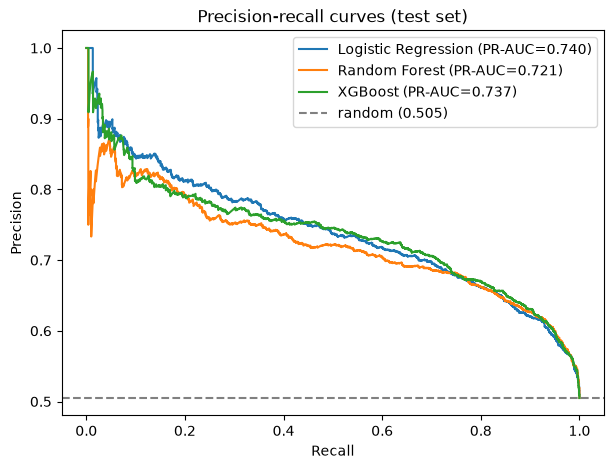

In [11]:
fig, ax = plt.subplots(figsize=(7, 5))
for name in models:
    p, r, _ = precision_recall_curve(y_test, test_scores[name])
    ax.plot(r, p, label=f"{name} (PR-AUC={average_precision_score(y_test, test_scores[name]):.3f})")
ax.axhline(y_test.mean(), color="grey", ls="--", label=f"random ({y_test.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall curves (test set)")
ax.legend()
plt.show()

## 4. Bootstrap confidence intervals

The test set has only a few thousand customers, so a single number can be misleading.
I resample the test set 1,000 times (with replacement) and recompute the metric each time.
The 2.5% and 97.5% percentiles give a 95% confidence interval.

In [12]:
def bootstrap(y_true, y_score, metric, n=1000, seed=42):
    rng = np.random.default_rng(seed)
    y_true, y_score = np.asarray(y_true), np.asarray(y_score)
    values = []
    for _ in range(n):
        idx = rng.integers(0, len(y_true), len(y_true))
        values.append(metric(y_true[idx], y_score[idx]))
    return np.array(values)

rows = []
for name in models:
    for metric_name, metric in [("PR-AUC", average_precision_score), ("ROC-AUC", roc_auc_score)]:
        b = bootstrap(y_test, test_scores[name], metric)
        rows.append({"model": name, "metric": metric_name,
                     "value": metric(y_test, test_scores[name]),
                     "CI low": np.percentile(b, 2.5), "CI high": np.percentile(b, 97.5)})
pd.DataFrame(rows).set_index(["metric", "model"]).sort_index()

value  CI low  CI high
metric  model                                      
PR-AUC  Logistic Regression  0.740   0.720    0.760
        Random Forest        0.721   0.700    0.743
        XGBoost              0.737   0.716    0.758
ROC-AUC Logistic Regression  0.762   0.748    0.776
        Random Forest        0.754   0.740    0.769
        XGBoost              0.766   0.752    0.780

Overlapping intervals do not tell us directly if one model is better than another. A **paired bootstrap**
(same resampled customers for both models) answers that: if the 95% interval of the difference
does not contain 0, the gap is significant.

In [13]:
def paired_diff(model_a, model_b, metric=average_precision_score, n=1000, seed=42):
    rng = np.random.default_rng(seed)
    y = np.asarray(y_test)
    a, b = test_scores[model_a], test_scores[model_b]
    diffs = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        diffs.append(metric(y[idx], a[idx]) - metric(y[idx], b[idx]))
    return np.mean(diffs), np.percentile(diffs, [2.5, 97.5])

for a, b in [("XGBoost", "Logistic Regression"), ("Random Forest", "Logistic Regression"), ("XGBoost", "Random Forest")]:
    mean, (lo, hi) = paired_diff(a, b)
    print(f"PR-AUC {a} - {b}: {mean:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]")

PR-AUC XGBoost - Logistic Regression: -0.004  95% CI [-0.013, +0.006]


PR-AUC Random Forest - Logistic Regression: -0.019  95% CI [-0.032, -0.005]


PR-AUC XGBoost - Random Forest: +0.016  95% CI [+0.004, +0.027]


- **XGBoost vs Logistic Regression**: the interval contains 0, so there is **no significant difference**.
- **Random Forest** is significantly (but slightly) worse than both.

The churn signal here is mostly *"how long since the last order"* and *"how many orders"*, which a linear model
on log-transformed features captures well. XGBoost is kept for the next steps because it ties with the baseline
and works directly with SHAP's tree explainer.

## 5. Choosing a decision threshold

The model gives a churn **probability**. Turning it into an alert needs a threshold, and every threshold is a trade-off:

- **Missed churners** (false negatives): customers who leave without any retention action
- **False alerts** (false positives): retention effort (discounts, calls) spent on customers who would have stayed anyway

The threshold is chosen on the **validation** set, then checked on the test set. I continue with XGBoost.

In [14]:
best = "XGBoost"
model = models[best]

def threshold_table(y_true, scores, thresholds):
    rows = []
    for t in thresholds:
        pred = (scores >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
        rows.append({"threshold": t, "precision": precision_score(y_true, pred, zero_division=0),
                     "recall": recall_score(y_true, pred), "f1": f1_score(y_true, pred),
                     "alerts": tp + fp, "missed churners": fn, "false alerts": fp})
    return pd.DataFrame(rows).set_index("threshold")

thresholds = np.round(np.arange(0.1, 0.91, 0.05), 2)
val_table = threshold_table(y_val, val_scores[best], thresholds)
val_table

,precision,recall,f1,alerts,missed churners,false alerts
threshold,,,,,,
0.100,0.664,0.996,0.797,4128,10,1387
0.150,0.680,0.991,0.807,4006,25,1280
0.200,0.691,0.988,0.813,3934,33,1216
0.250,0.702,0.980,0.818,3842,54,1145
0.300,0.715,0.969,0.823,3729,86,1064
0.350,0.726,0.953,0.824,3612,128,989
0.400,0.741,0.938,0.828,3482,170,901
0.450,0.755,0.913,0.826,3327,240,816
0.500,0.770,0.886,0.824,3165,314,728


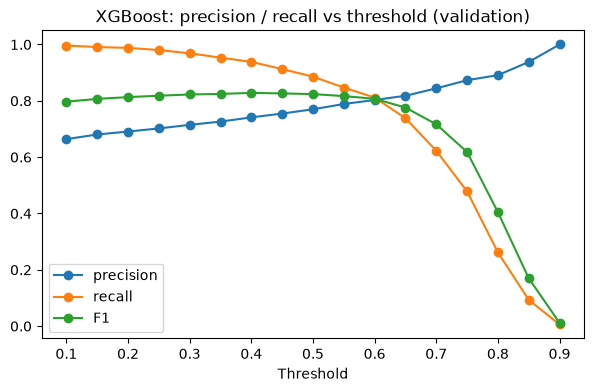

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(val_table.index, val_table["precision"], marker="o", label="precision")
ax.plot(val_table.index, val_table["recall"], marker="o", label="recall")
ax.plot(val_table.index, val_table["f1"], marker="o", label="F1")
ax.set_xlabel("Threshold")
ax.set_title(f"{best}: precision / recall vs threshold (validation)")
ax.legend()
plt.show()

Three ways to pick the threshold:

1. **Default 0.5**
2. **Best F1**: balance between precision and recall
3. **Catch at least 80% of churners**: the highest threshold that keeps recall ≥ 0.80 (fewest false alerts at that recall)

In [16]:
t_f1 = val_table["f1"].idxmax()
t_recall80 = val_table[val_table["recall"] >= 0.80].index.max()
chosen = {"default 0.5": 0.5, "best F1": t_f1, "recall >= 80%": t_recall80}
print(chosen)

rows = []
for label, t in chosen.items():
    pred = (test_scores[best] >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    p_ci = np.percentile(bootstrap(y_test, pred, precision_score), [2.5, 97.5])
    r_ci = np.percentile(bootstrap(y_test, pred, recall_score), [2.5, 97.5])
    rows.append({"strategy": label, "threshold": t,
                 "precision": f"{tp / (tp + fp):.3f} [{p_ci[0]:.3f}, {p_ci[1]:.3f}]",
                 "recall": f"{tp / (tp + fn):.3f} [{r_ci[0]:.3f}, {r_ci[1]:.3f}]",
                 "alerts": tp + fp, "missed churners": fn, "false alerts": fp})
pd.DataFrame(rows).set_index("strategy")

{'default 0.5': 0.5, 'best F1': np.float64(0.4), 'recall >= 80%': np.float64(0.6)}


,threshold,precision,recall,alerts,missed churners,false alerts
strategy,,,,,,
default 0.5,0.500,"0.630 [0.614, 0.647]","0.899 [0.887, 0.911]",3120,222,1153
best F1,0.400,"0.604 [0.588, 0.621]","0.942 [0.933, 0.952]",3413,126,1350
recall >= 80%,0.600,"0.663 [0.646, 0.681]","0.819 [0.802, 0.835]",2703,396,910


- Lowering the threshold catches more churners but sends more false alerts: from 0.6 to 0.4,
  missed churners drop from ~400 to ~130, while false alerts rise from ~900 to ~1,350.
- On the test set precision is lower than on validation (~0.60-0.66 vs ~0.74-0.80) for the same threshold:
  fewer customers actually churn in the Christmas season, so more alerts are false. In practice the threshold
  should be re-checked when the season changes.
- The right choice depends on cost: if a retention offer is cheap (an email), a low threshold (0.4) is fine;
  if it is expensive (a discount, a phone call), a higher one (0.6) wastes less budget.

I keep the **best-F1 threshold** for the rest of the analysis.

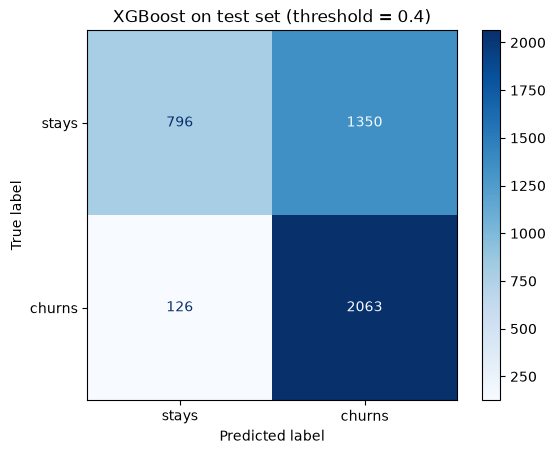

In [17]:
threshold = t_f1
test["score"] = test_scores[best]
test["pred"] = (test["score"] >= threshold).astype(int)

ConfusionMatrixDisplay.from_predictions(y_test, test["pred"], display_labels=["stays", "churns"], cmap="Blues")
plt.title(f"{best} on test set (threshold = {threshold})")
plt.show()

## 6. Error analysis: false positives and false negatives

- **False positive**: predicted to churn, but the customer bought again
- **False negative**: predicted to stay, but the customer did not buy in the next 90 days

In [18]:
test["outcome"] = np.select(
    [(test["pred"] == 1) & (test["churn"] == 1), (test["pred"] == 1) & (test["churn"] == 0),
     (test["pred"] == 0) & (test["churn"] == 1)],
    ["TP", "FP", "FN"], default="TN")

print(test["outcome"].value_counts().to_dict())
test.groupby("outcome")[features + ["score"]].median().T[["TP", "FP", "FN", "TN"]]

{'TP': 2063, 'FP': 1350, 'TN': 796, 'FN': 126}


outcome,TP,FP,FN,TN
recency_days,195.000,111.000,28.000,23.000
tenure_days,342.000,385.000,568.500,583.000
n_orders,2.000,3.000,11.000,13.000
total_spend,589.270,917.640,3892.510,5003.015
avg_order_value,261.553,292.845,359.118,362.183
orders_last_90d,0.000,0.000,1.500,2.000
spend_last_90d,0.000,0.000,434.990,734.660
avg_days_between_orders,126.000,88.583,49.700,37.771
n_products,31.000,48.000,124.000,148.000
is_uk,1.000,1.000,1.000,1.000


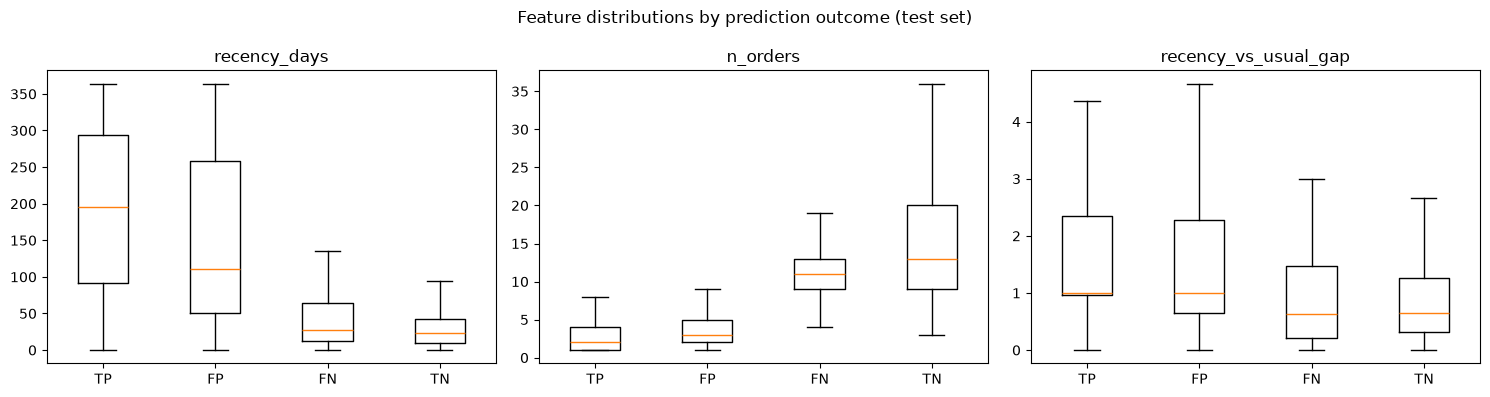

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["recency_days", "n_orders", "recency_vs_usual_gap"]):
    data = [test.loc[test["outcome"] == o, col] for o in ["TP", "FP", "FN", "TN"]]
    ax.boxplot(data, tick_labels=["TP", "FP", "FN", "TN"], showfliers=False)
    ax.set_title(col)
plt.suptitle("Feature distributions by prediction outcome (test set)")
plt.tight_layout()
plt.show()

In [20]:
# most confident mistakes
show = ["customer_id", "score"] + features
print("False positives with the highest churn score:")
display(test[test["outcome"] == "FP"].nlargest(5, "score")[show])
print("False negatives with the lowest churn score:")
display(test[test["outcome"] == "FN"].nsmallest(5, "score")[show])

False positives with the highest churn score:


,customer_id,score,recency_days,tenure_days,n_orders,total_spend,avg_order_value,orders_last_90d,spend_last_90d,avg_days_between_orders,n_products,is_uk,recency_vs_usual_gap
1880,14908,0.902,363,363,1,104.100,104.100,0.000,0.000,363.000,5,1,0.997
533,13083,0.896,325,325,1,91.680,91.680,0.000,0.000,325.000,4,1,0.997
765,13403,0.894,287,623,2,154.500,77.250,0.000,0.000,335.000,6,1,0.854
944,13651,0.892,281,281,1,132.650,132.650,0.000,0.000,281.000,8,1,0.996
1579,14494,0.888,301,631,2,261.900,130.950,0.000,0.000,329.000,10,1,0.912


False negatives with the lowest churn score:


,customer_id,score,recency_days,tenure_days,n_orders,total_spend,avg_order_value,orders_last_90d,spend_last_90d,avg_days_between_orders,n_products,is_uk,recency_vs_usual_gap
4185,18073,0.054,14,97,12,3877.520,323.127,10.000,3636.440,7.182,23,1,1.711
2140,15260,0.057,0,633,25,9188.230,367.529,3.000,928.170,25.958,186,1,0.000
2358,15581,0.066,20,637,38,7794.590,205.121,5.000,3045.010,16.216,542,1,1.162
3069,16550,0.069,8,637,18,9435.130,524.174,3.000,1260.060,36.588,274,1,0.213
532,13082,0.074,26,617,21,7335.750,349.321,4.000,1653.450,29.150,99,1,0.862


**False positives** (predicted churn, but came back): mostly customers with **1-2 small orders, last seen 9-12 months
ago** (Sep-Nov 2010). They look gone, but they are **seasonal / once-a-year buyers** who come back for Christmas 2011.
With only two years of data, the training snapshots never show this pattern, so the model cannot learn it.

**False negatives** (predicted to stay, but churned): the opposite profile, **very active customers** (median 11 orders,
last order ~4 weeks ago) who suddenly stop. Nothing in their past behaviour announces it; catching them would need
other data (complaints, delivery issues, competitor prices...).

## 7. Explaining predictions with SHAP

SHAP splits each prediction into contributions from each feature (in log-odds for XGBoost):
red pushes the churn score up, blue pushes it down.

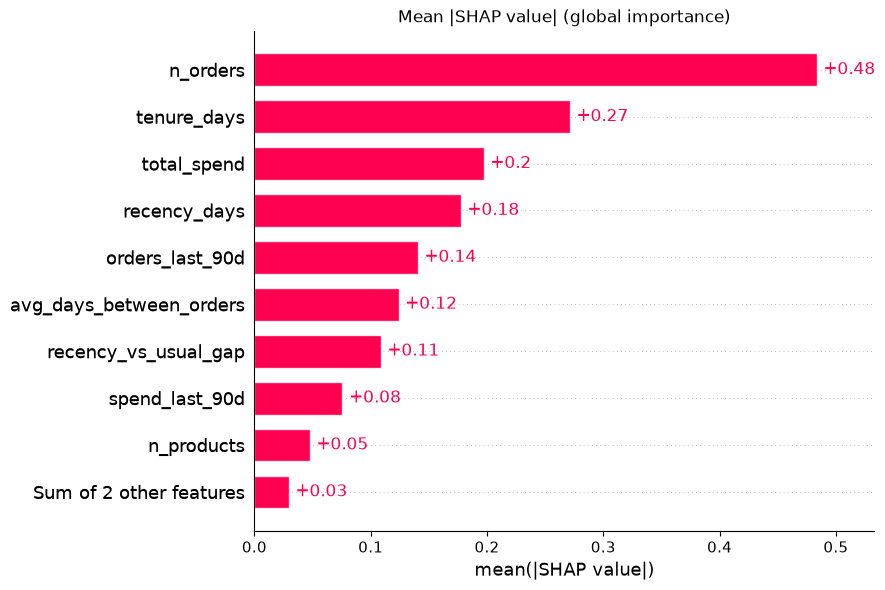

In [21]:
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)

shap.plots.bar(shap_values, show=False)
plt.title("Mean |SHAP value| (global importance)")
plt.show()

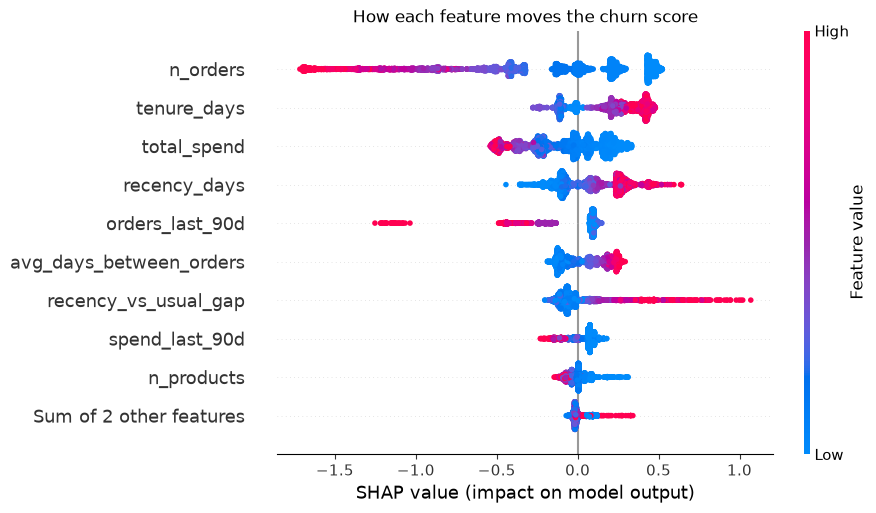

In [22]:
shap.plots.beeswarm(shap_values, show=False)
plt.title("How each feature moves the churn score")
plt.show()

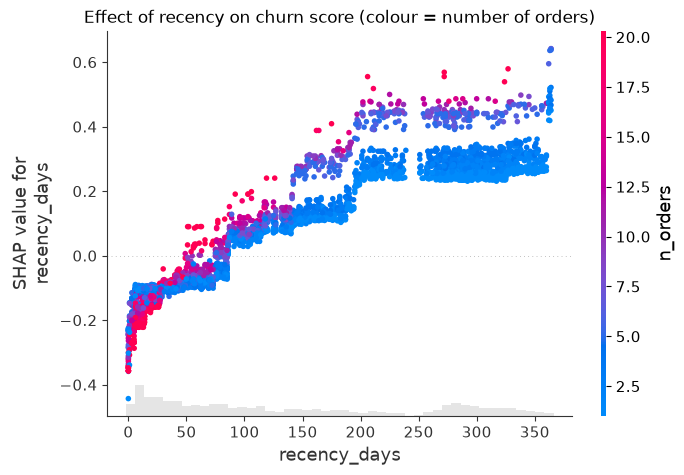

In [23]:
shap.plots.scatter(shap_values[:, "recency_days"], color=shap_values[:, "n_orders"], show=False)
plt.title("Effect of recency on churn score (colour = number of orders)")
plt.show()

- **Number of orders** is the strongest feature: one-off buyers get a much higher churn score, loyal buyers a much lower one.
- **Recency** pushes the score up steadily, with a jump after ~200 days without an order.
- **Orders in the last 90 days** strongly lower the score: a recent order is a good sign of activity.
- **Tenure** pushes the score up: for the same number of orders, a customer who has been around longer
  buys less often.
- **recency_vs_usual_gap** has a long red tail: customers who are much "later" than their usual rhythm get a higher score.

### Individual explanations

One customer from each interesting group: a correctly caught churner, the most confident false alert,
and the most confident missed churner.

True positive: customer 14086, score = 0.916, churned = 1


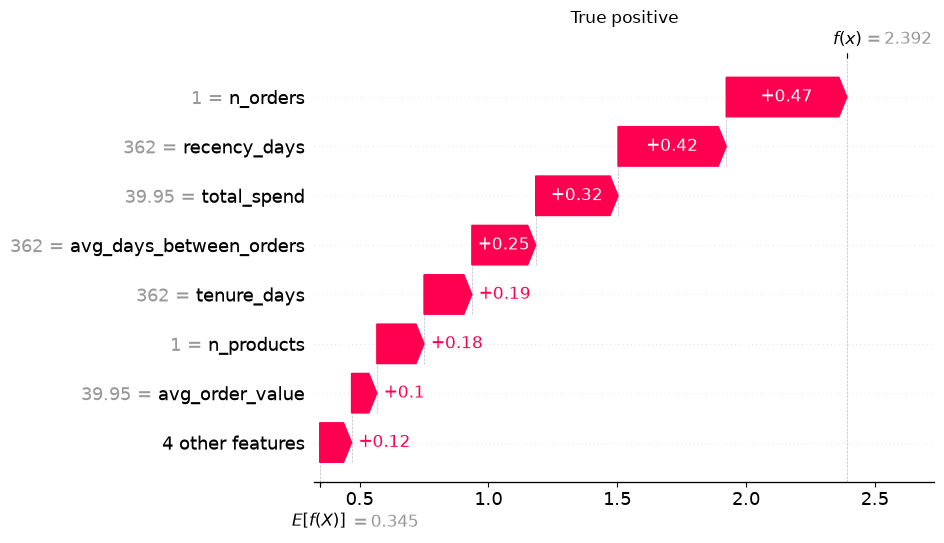

False positive: customer 14908, score = 0.902, churned = 0


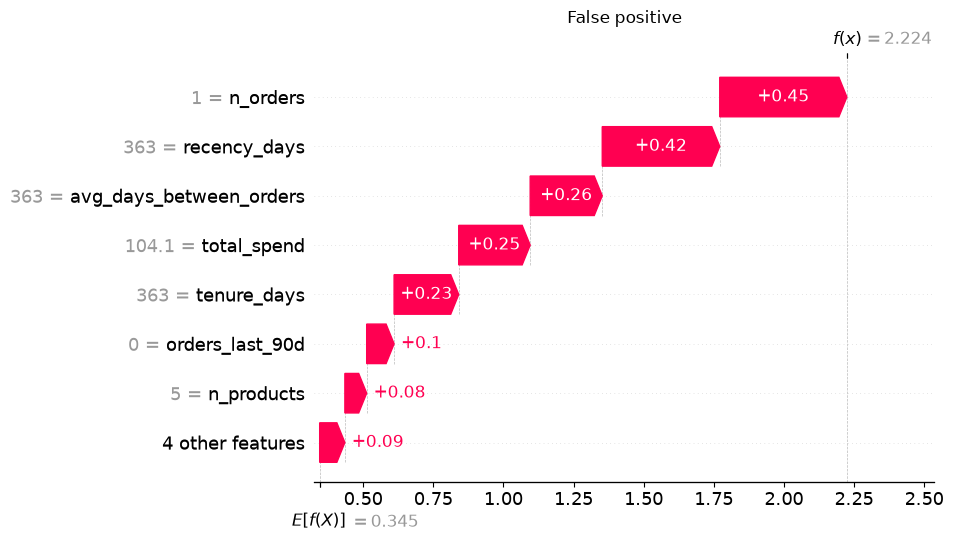

False negative: customer 18073, score = 0.054, churned = 1


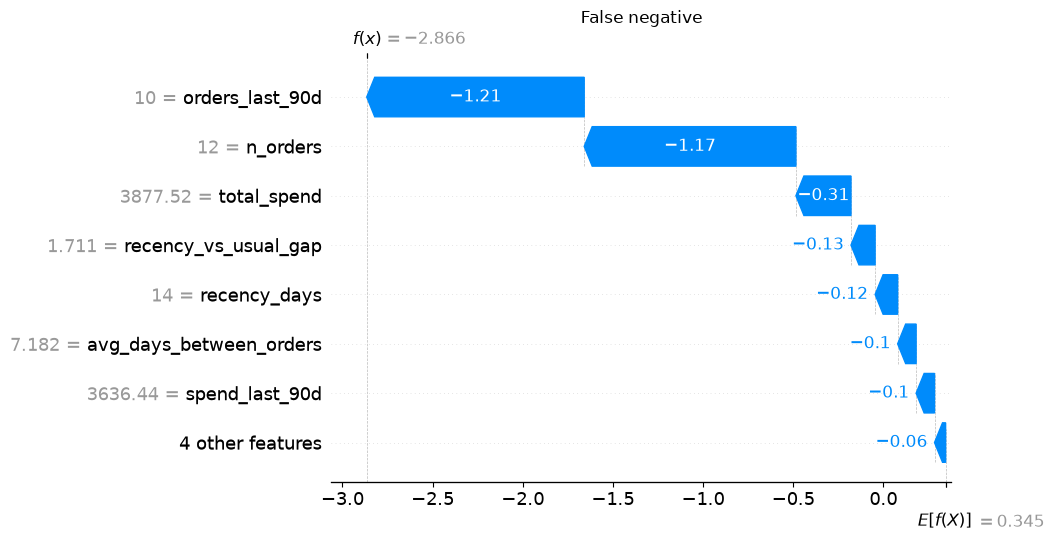

In [24]:
def explain(i, title):
    row = test.loc[i]
    print(f"{title}: customer {row['customer_id']}, score = {row['score']:.3f}, churned = {row['churn']}")
    shap.plots.waterfall(shap_values[i], max_display=8, show=False)
    plt.title(title)
    plt.show()

explain(test[test["outcome"] == "TP"]["score"].idxmax(), "True positive")
explain(test[test["outcome"] == "FP"]["score"].idxmax(), "False positive")
explain(test[test["outcome"] == "FN"]["score"].idxmin(), "False negative")

- **True positive**: few orders and a long time since the last one, every feature points to churn.
- **False positive**: a single small order exactly ~1 year ago. The model reads it as "gone", the customer was an annual buyer.
- **False negative**: 10 orders in the last 90 days, so the model is very confident the customer stays, but they stopped buying.

## 8. Conclusion

| | Result |
|---|---|
| Best PR-AUC (test) | 0.740 [0.720, 0.760] (Logistic Regression), XGBoost 0.737 [0.716, 0.758], random = 0.505 |
| Model comparison | XGBoost ≈ Logistic Regression (difference not significant), Random Forest slightly worse |
| Threshold 0.4 (best F1) | recall 0.94, precision 0.60 on test |
| Threshold 0.6 | recall 0.82, precision 0.66, ~440 fewer false alerts |
| Main drivers (SHAP) | number of orders, recency, orders in the last 90 days, tenure |

**Takeaways**
- Churn in this retail data is driven by simple purchase behaviour (how often, how recently). A well-prepared
  linear baseline is as good as gradient boosting.
- The decision threshold is a business choice (cost of a missed churner vs cost of a false alert), and it should be
  monitored because the churn rate changes with the season.
- Main errors: seasonal buyers flagged as churners (false alerts), and active customers who stop suddenly (missed churners).

**Limitations and next steps**
- Only two years of data: not enough to learn yearly (Christmas) buying patterns. More history would allow
  features like "bought in the same season last year".
- Customers appear in several training snapshots, so training rows are not fully independent.
- Probabilities could be calibrated per season, and the threshold could be set from real retention costs.